# Pulse propagation in 2D (time domain from a frequency sweep)
It follows the pulse2d example of the MATLAB WaveSim implementation.

Simulate the time-domain propagation of a band-limited plane-wave pulse through a 2D
homogeneous medium. The pulse is built up from ``Nfreq`` independent frequency-domain
Helmholtz simulations (one per wavelength in a Gaussian-windowed spectrum). The complex
fields are stacked along a frequency axis and an inverse FFT recovers the field as a
function of time, which is then animated.

Size: 5 solves, the largest 0.012 Mvoxel including boundaries, 0.0003 GB of memory (service estimate).

Simulation: 1/5

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : cb292a7e-57e6-4f87-82ce-8c3ae33a2beb
  Version   : 85237c52-ceb2-4b82-82b1-ca6248c295a8
  Command   : 94c8d8f0-c72d-4409-a562-cc94c7ab2fff
  Mode      : Helmholtz (scalar)
  Domain    : 64x128x1 voxels  lambda=0.8 um  dx=0.250 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Simulation: 2/5

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : f935c1f4-5edd-419e-bdf3-9a5f48d0a296
  Version   : 2decdd4b-57c2-4581-a3c7-d6d4931f8ea1
  Command   : a4d948ed-d53d-4721-a481-7f9484276fa1
  Mode      : Helmholtz (scalar)
  Domain    : 64x128x1 voxels  lambda=0.9 um  dx=0.250 um
  Engine    : Any (auto-select)  |  GPU: auto
  Thres

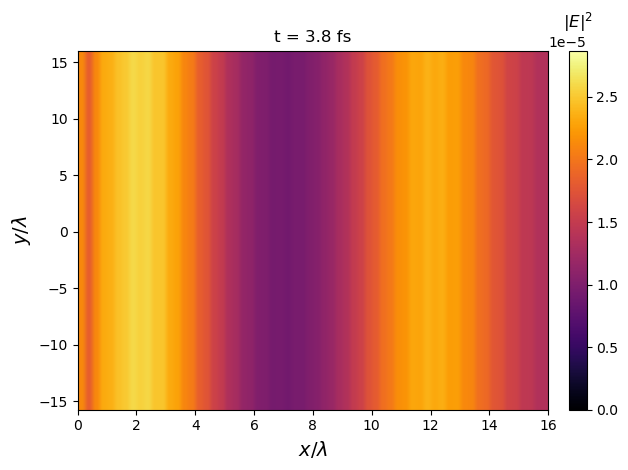

In [1]:
import numpy as np
from time import time
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.signal.windows import gaussian

from wavesimpro import configure, simulate
from wsutils import output_dir

NAME = "hmhz_pulse2d"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

# Parameters
PPW = 4                       # points per wavelength
wavelength = 1.0              # center wavelength in vacuum (μm)
pixel_size = wavelength / PPW  # grid pixel size (μm)

# Size of the medium (in pixels): axis 0 = x (propagation / absorbing),
# axis 1 = y (transverse / periodic).
n_x = PPW * 16  # 64 pixels along the propagation direction (absorbing boundary)
n_y = PPW * 32  # 128 pixels along the transverse direction (periodic boundary)

# Homogeneous medium: refractive index 1 everywhere -> permittivity = 1
permittivity = np.ones((n_x, n_y, 1), dtype=np.complex64)

# Source spectrum: a band of frequencies (0.8-1.2 um) with a Gaussian envelope.
Nfreq = 5                                          # number of independent frequencies simulated
lambda_set = np.linspace(0.8, 1.2, Nfreq) * wavelength  # source bandwidth (μm)
source_spectrum = gaussian(Nfreq, (Nfreq - 1) / (2 * 4))  # Gaussian window, sigma = (Nfreq - 1) / 8

# Run a wavesim simulation for every source frequency and store the resulting field.
E_set = np.zeros((n_x, n_y, Nfreq), dtype=np.complex64)
start = time()
for f in range(Nfreq):
    print(f"Simulation: {f + 1}/{Nfreq}")

    # Plane wave spanning the full transverse (y) extent at the x-entry plane (x = 0),
    # scaled by the spectral amplitude for this frequency.
    source_values = np.full((1, n_y, 1), source_spectrum[f], dtype=np.complex64)
    source_position = [0, 0, 0]  # entry plane, in pixels

    # Periodic in y (and the singleton z), absorbing in x.
    u, iterations, residual_norm = simulate(
        permittivity=permittivity,
        sources=[(source_values, source_position)],
        wavelength=lambda_set[f],
        pixel_size=pixel_size,
        boundary_width=4.0,                 # μm (= 4*PPW = 16 px), added in x only
        periodic=(False, True, True),
    )
    E_set[:, :, f] = u  # u is a host numpy array of shape (n_x, n_y)
print(f"Total simulation time: {time() - start:.2f} s")

# Field in the time domain: inverse Fourier transform E(frequency) -> E(time).
E_time = np.fft.ifftshift(np.fft.ifft(E_set, n=Nfreq, axis=2), axes=2)

# Axes (in μm; with wavelength = 1 μm these equal x/λ and y/λ).
x = np.arange(1, n_x + 1) * pixel_size
y = np.arange(-n_y // 2 + 1, n_y // 2 + 1) * pixel_size

# Time axis from the frequency spacing: f = c*k0 [Hz].
c = 3e8
freq = c * 2 * np.pi / (lambda_set * 1e-6)
t_set = np.arange(-Nfreq // 2 + 1, Nfreq // 2 + 1) * (1.0 / (2 * (freq[0] - freq[1])))

# Keep only positive times.
keep = t_set >= 0
E_time = E_time[:, :, keep]
t_set = t_set[keep] * 1e15  # → fs

# Animate the intensity |E(t)|^2 over time.
intensity = np.abs(E_time) ** 2
Imax = intensity.max()
n_frames = intensity.shape[2]

fig, ax = plt.subplots()
extent = [0, n_x * pixel_size, y.min(), y.max()]
# .T puts x on the horizontal axis and y on the vertical axis.
im = ax.imshow(intensity[:, :, 0].T, extent=extent, origin='lower',
               vmin=0, vmax=Imax, cmap='inferno', aspect='auto')
ax.set_xlabel(r"$x / \lambda$", fontsize=14)
ax.set_ylabel(r"$y / \lambda$", fontsize=14)
title = ax.set_title(f"t = {t_set[0]:.1f} fs")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.set_title(r"$|E|^2$")


def update(frame):
    im.set_data(intensity[:, :, frame].T)
    title.set_text(f"t = {t_set[frame]:.1f} fs")
    return im, title


anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=100, blit=False)
plt.tight_layout()

# Save the animation as a GIF in OUTPUT_DIR.
gif_path = f"{OUTPUT_DIR}/{NAME}.gif"
try:
    anim.save(gif_path, writer=animation.PillowWriter(fps=10))
    print(f"Saved animation to output/{NAME}/{NAME}.gif")
except Exception as exc:  # noqa: BLE001 - saving is best-effort; still show the animation
    print(f"Could not save animation ({exc}).")

plt.show()